# FairCredit AI — Model Training and Evaluation

## Objective
Train and compare four classification models that predict whether a customer defaults next month.

Models:
1. Logistic Regression
2. Decision Tree
3. Random Forest
4. K-Nearest Neighbors (KNN)

We will use a stratified train/test split so the target proportions are similar in both sets. We will fit preprocessing only on the training data to avoid data leakage.

**Target:** `default payment next month`  
**Important:** This is an educational prototype using historical Taiwan data, not a real lending decision system.

In [10]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, ConfusionMatrixDisplay,
    classification_report
)

# Make results reproducible
RANDOM_STATE = 42

In [11]:
# Load the dataset
df = pd.read_excel(
    "../data/default of credit card clients.xls",
    header=1
)

# Rename target to make it easier to use
df = df.rename(columns={"default payment next month": "DEFAULT"})

print("Dataset shape:", df.shape)
display(df.head())

/tmp/ipykernel_55783/713394544.py:2: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  df = pd.read_excel(


Dataset shape: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


## 1. Prepare features and target

We remove `ID` because it is only an identifier. The target column is kept separate from the input features.

In [12]:
# Separate input features (X) and target (y)
X = df.drop(columns=["ID", "DEFAULT"])
y = df["DEFAULT"]

print("Number of input features:", X.shape[1])
print("Target counts:")
print(y.value_counts())

Number of input features: 23
Target counts:
DEFAULT
0    23364
1     6636
Name: count, dtype: int64


## 2. Split the data

We keep 20% of the data for final testing. `stratify=y` preserves the approximate default/non-default proportions in both sets.

In [13]:
# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target proportions:")
print(y_test.value_counts(normalize=True).round(3))

Training rows: 24000
Testing rows: 6000

Training target proportions:
DEFAULT
0    0.779
1    0.221
Name: proportion, dtype: float64

Testing target proportions:
DEFAULT
0    0.779
1    0.221
Name: proportion, dtype: float64


## 3. Prepare the columns

The coded demographic columns and repayment-status columns represent categories, so we one-hot encode them. We scale continuous money/age features for models sensitive to feature scale, such as Logistic Regression and KNN. The preprocessing steps are inside each pipeline, so they are learned from training data only.

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Categorical columns
categorical_cols = [
    "SEX", "EDUCATION", "MARRIAGE",
    "PAY_0", "PAY_2", "PAY_3",
    "PAY_4", "PAY_5", "PAY_6"
]

# Numerical columns
numerical_cols = [
    "LIMIT_BAL", "AGE",
    "BILL_AMT1", "BILL_AMT2", "BILL_AMT3",
    "BILL_AMT4", "BILL_AMT5", "BILL_AMT6",
    "PAY_AMT1", "PAY_AMT2", "PAY_AMT3",
    "PAY_AMT4", "PAY_AMT5", "PAY_AMT6"
]

# Create the preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("numerical", StandardScaler(), numerical_cols)
    ]
)

print("Preprocessor defined successfully!")

Preprocessor defined successfully!


## 4. Create the four models

Each model uses the same preprocessing and the same train/test split, making the comparison more consistent.

Each pipeline gets its own copy of the preprocessor (`clone(preprocessor)`). This prevents one model's fit from overwriting the preprocessing state used by another model.

In [15]:
# Define the four models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        max_depth=8
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=1
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        algorithm="brute",
        n_jobs=1
    )
}

# Create a pipeline for each model
pipelines = {}

for name, model in models.items():
    pipelines[name] = Pipeline([
        # Give each model its own independent fitted preprocessor
        ("preprocessing", clone(preprocessor)),
        ("model", model)
    ])

print("Models prepared:", list(pipelines.keys()))

Models prepared: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'KNN']


## 5. Train and compare models

We report accuracy, precision, recall, F1-score, ROC-AUC, and average precision (PR-AUC-style summary). Since defaults are the minority class, do not use accuracy alone to select a model.

In [16]:
# Train and compare all four models
results = []
trained_models = {}

for name, pipeline in pipelines.items():

    print("Training:", name, flush=True)

    # Use a smaller, representative sample for KNN
    if name == "KNN":
        X_knn, _, y_knn, _ = train_test_split(
            X_train,
            y_train,
            train_size=3000,
            random_state=42,
            stratify=y_train
        )

        pipeline.fit(X_knn, y_knn)

    else:
        # Train the other models on all training data
        pipeline.fit(X_train, y_train)

    # Predict on the same untouched test set
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "Average Precision": average_precision_score(
            y_test, y_prob
        )
    })

    trained_models[name] = pipeline
    print(name, "completed", flush=True)

# Display the comparison table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

display(results_df.round(3))

Training: Logistic Regression
Logistic Regression completed
Training: Decision Tree
Decision Tree completed
Training: Random Forest
Random Forest completed
Training: KNN
KNN completed


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,Logistic Regression,0.817,0.661,0.352,0.459,0.758,0.528
1,Random Forest,0.816,0.645,0.369,0.469,0.752,0.530
2,Decision Tree,0.812,0.645,0.328,0.435,0.730,0.486
3,KNN,0.790,0.552,0.277,0.369,0.678,0.392


### individually for Knn testing using batch wise due to crash , 24000 x 6000 record = 144 million training-test record pairs


In [17]:
import numpy as np
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    classification_report
)

# Create a fresh KNN pipeline
knn_full = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("model", KNeighborsClassifier(
        n_neighbors=5,
        algorithm="brute",
        n_jobs=1
    ))
])

# Train on all 24,000 training records
print("Training KNN...", flush=True)
knn_full.fit(X_train, y_train)
print("Training completed!", flush=True)

# Transform test data only once
X_test_processed = knn_full.named_steps["preprocessing"].transform(X_test)

# Predict in smaller batches
# Get the fitted KNN model
knn_model = knn_full.named_steps["model"]

# Store predictions and probabilities
predictions = []
probabilities = []

# Get total number of test records
total_records = X_test_processed.shape[0]

# Predict in batches of 500 records
for start in range(0, total_records, 500):
    end = min(start + 500, total_records)

    # Select the current batch
    batch = X_test_processed[start:end]

    # Predict class labels and default probabilities
    predictions.extend(knn_model.predict(batch))
    probabilities.extend(knn_model.predict_proba(batch)[:, 1])

    print(f"Processed {end}/{total_records} test records", flush=True)

# Convert results into NumPy arrays
knn_predictions = np.array(predictions)
knn_probabilities = np.array(probabilities)

# Evaluate the model
print("\nClassification Report:")
print(classification_report(
    y_test,
    knn_predictions,
    target_names=["No default (0)", "Default (1)"],
    zero_division=0
))

print("Accuracy:", accuracy_score(y_test, knn_predictions))
print("Precision:", precision_score(y_test, knn_predictions, zero_division=0))
print("Recall:", recall_score(y_test, knn_predictions, zero_division=0))
print("F1-score:", f1_score(y_test, knn_predictions, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, knn_probabilities))
print("Average Precision:", average_precision_score(y_test, knn_probabilities))

Training KNN...


Training completed!
Processed 500/6000 test records
Processed 1000/6000 test records
Processed 1500/6000 test records
Processed 2000/6000 test records
Processed 2500/6000 test records
Processed 3000/6000 test records
Processed 3500/6000 test records
Processed 4000/6000 test records
Processed 4500/6000 test records
Processed 5000/6000 test records
Processed 5500/6000 test records
Processed 6000/6000 test records

Classification Report:
                precision    recall  f1-score   support

No default (0)       0.83      0.93      0.88      4673
   Default (1)       0.56      0.33      0.42      1327

      accuracy                           0.79      6000
     macro avg       0.70      0.63      0.65      6000
  weighted avg       0.77      0.79      0.77      6000

Accuracy: 0.7948333333333333
Precision: 0.5609137055837563
Recall: 0.33308214016578747
F1-score: 0.41796690307328604
ROC-AUC: 0.6991676115303309
Average Precision: 0.41384959134245236


## 6. Compare model performance

The bar chart compares the selected metrics. Use recall and precision alongside ROC-AUC and F1-score, especially because the target classes are imbalanced.

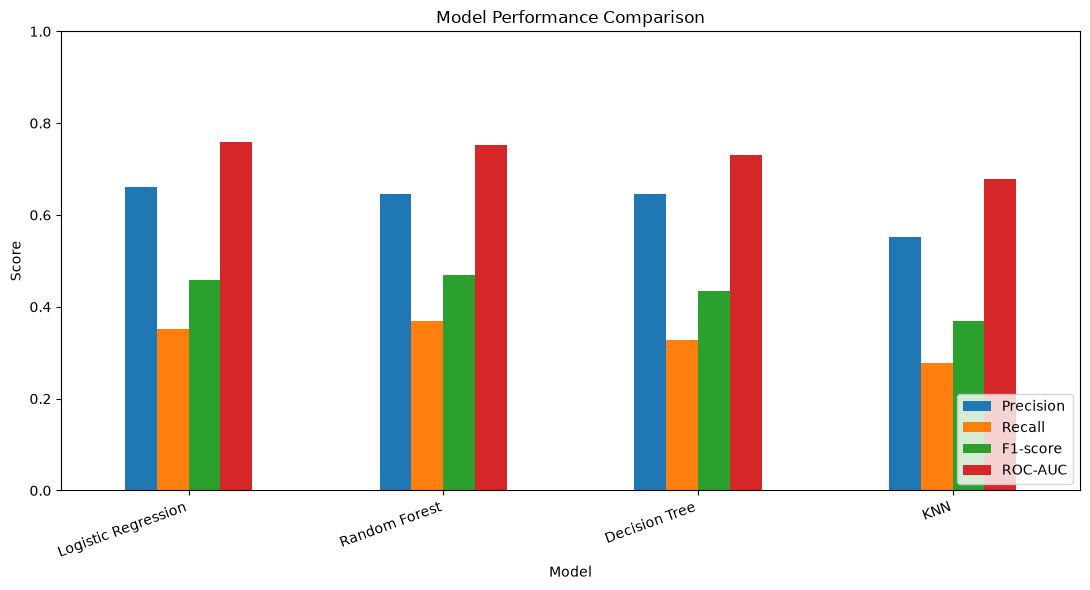

In [18]:
# Plot model comparison
metrics_to_plot = ["Precision", "Recall", "F1-score", "ROC-AUC"]

results_df.set_index("Model")[metrics_to_plot].plot(
    kind="bar", figsize=(11, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 7. Inspect the best ROC-AUC model

This selects the model with the highest ROC-AUC on the test set for a first look. This test-set comparison is for learning; for rigorous model selection, compare candidates using cross-validation on training data and use the test set only once for final evaluation.

In [19]:
# Select the model with the highest ROC-AUC
results_df = results_df.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]

print("Highest test ROC-AUC model:", best_model_name)
print("Test ROC-AUC:", round(results_df.loc[0, "ROC-AUC"], 3))

# Predict using the exact test features used for evaluation
best_predictions = best_model.predict(X_test)

print("\nClassification report:")
print(classification_report(
    y_test,
    best_predictions,
    labels=[0, 1],
    target_names=["No default (0)", "Default (1)"],
    zero_division=0
))


Highest test ROC-AUC model: Logistic Regression
Test ROC-AUC: 0.758

Classification report:
                precision    recall  f1-score   support

No default (0)       0.84      0.95      0.89      4673
   Default (1)       0.66      0.35      0.46      1327

      accuracy                           0.82      6000
     macro avg       0.75      0.65      0.67      6000
  weighted avg       0.80      0.82      0.79      6000



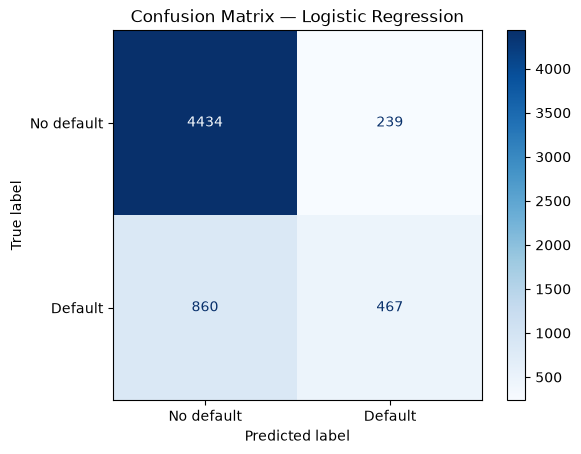

In [20]:
# Display confusion matrix for the selected model
ConfusionMatrixDisplay.from_estimator(
    best_model,
    X_test,
    y_test,
    display_labels=["No default", "Default"],
    cmap="Blues"
)
plt.title(f"Confusion Matrix — {best_model_name}")
plt.show()

## 8. Write down your findings

After running all cells, use your actual results to answer:

1. Which model has the highest ROC-AUC?
    Logistic Regression, with a ROC-AUC of approximately 0.758

2. Which model has the highest recall for default customers?
    Random Forest, with a recall of approximately 0.369 (36.9%)

3. Which model has the best F1-score?
    Random Forest, with an F1-score of approximately 0.469

4. What kinds of mistakes appear in the confusion matrix?
    The confusion matrix shows two main types of mistakes:
    - False negatives: Customers who actually defaulted but were predicted as non-defaulters.
    - False positives: Customers who did not default but were predicted as defaulters.

5. Which model would you investigate further, and why?
    I would investigate Random Forest further because it achieved the highest recall (36.9%) and F1-score (0.469) in the earlier comparison. However, Logistic Regression had the highest ROC-AUC (0.758), making it a strong alternative.


## Conclusion

We trained four classification models using a stratified train/test split and consistent preprocessing. We compared their test-set metrics and inspected the selected model's classification report and confusion matrix.